# Práctica 2 · Del aprendizaje profundo de Andrew Ng a TensorFlow/Keras
**Clasificación multiclase MNIST · MLP · flujo train/dev/test**

**Objetivo.** Aplicar sin reprogramar backpropagation los conceptos ya estudiados: partición de datos, normalización, inicialización, mini-batches, optimizadores, regularización, selección de hiperparámetros y evaluación final. Usaremos `tf.keras` como herramienta de implementación.

**Pipeline:** preparar datos → modelo base → comparar optimizadores → regularización → búsqueda aleatoria → seleccionar en dev → evaluar una sola vez en test → evaluación práctica individual.

> Las secciones con experimentos se pueden limitar en número de épocas para trabajar en Colab CPU. `test` permanece reservado hasta el final.

## 1. Entorno y reproducibilidad
Fijamos semillas para comparar configuraciones.

In [4]:
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, log_loss, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: []


## 2. Datos: **train / dev / test**
MNIST viene con 60,000 imágenes de entrenamiento y 10,000 de prueba. Separamos las primeras en **54,000 train y 6,000 dev** de forma estratificada. `dev` sirve para elegir hiperparámetros y diagnosticar; `test` solo para el reporte final. Las tres particiones son disjuntas por construcción.

Las imágenes tienen tamaño `(28, 28)`; las etiquetas son enteros de 0 a 9.

In [5]:
# Carga MNIST: 60,000 imágenes de entrenamiento y 10,000 de prueba.
(imagenes_all, etiquetas_all), (imagenes_test, y_test) = tf.keras.datasets.mnist.load_data()

# Divide los 60,000 ejemplos en train (54,000) y dev (6,000).
# stratify conserva la proporción de las 10 clases en ambos conjuntos.
idx_train, idx_dev = train_test_split(
    np.arange(len(etiquetas_all)), test_size=6000,
    stratify=etiquetas_all, random_state=SEED)

# Obtiene las imágenes y etiquetas correspondientes a cada partición.
imagenes_train, y_train = imagenes_all[idx_train], etiquetas_all[idx_train]
imagenes_dev, y_dev = imagenes_all[idx_dev], etiquetas_all[idx_dev]

C = 10  # Número de clases: dígitos del 0 al 9.

# Verifica que train y dev no compartan índices (prevención de fuga de datos); aunque aquí no ocurre, splitting por idx
assert len(set(idx_train).intersection(idx_dev)) == 0

# Muestra el número de ejemplos y las dimensiones de cada imagen (28 × 28).
print("Train/dev/test:", len(y_train), len(y_dev), len(y_test))
print("Forma de una imagen:", imagenes_train[0].shape)

# Muestra cuántos ejemplos de cada clase hay en train, dev y test.
display(pd.DataFrame({
    "train": np.bincount(y_train, minlength=C), # bincount() cuenta las imágenes de cada clase (0–9) para revisar su distribución.
    "dev": np.bincount(y_dev, minlength=C),
    "test": np.bincount(y_test, minlength=C)
}, index=range(C)))

Train/dev/test: 54000 6000 10000
Forma de una imagen: (28, 28)


,train,dev,test
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974
9,5354,595,1009


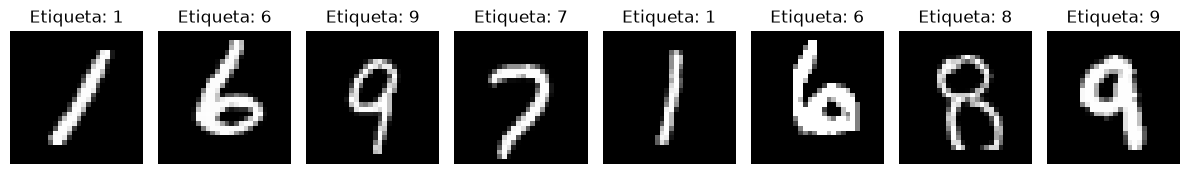

In [6]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, np.random.default_rng(SEED).choice(len(y_train), 8, replace=False)):
    ax.imshow(imagenes_train[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Etiqueta: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Normalización de entradas y dimensiones
Dividimos cada píxel entre 255 para obtener valores en `[0,1]`. En este caso el factor es conocido y no se estima con dev/test. En datos reales, si utilizamos media y desviación estándar, debemos **ajustarlas solamente con train** y aplicarlas sin recalcular a dev/test.

La capa `Flatten` transformará `(t,28,28)` en `(t,784)`; **t** es el tamaño del mini-batch. Mantenemos las etiquetas como enteros y utilizamos `SparseCategoricalCrossentropy` (equivalente a CE multiclase con etiquetas one-hot, pero sin materializar one-hot).

In [7]:
X_train = imagenes_train.astype("float32") / 255.0
X_dev = imagenes_dev.astype("float32") / 255.0
X_test = imagenes_test.astype("float32") / 255.0
assert X_train.shape == (54000, 28, 28)
assert X_dev.shape == (6000, 28, 28)
assert X_test.shape == (10000, 28, 28)
assert X_train.min() >= 0 and X_train.max() <= 1
print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)

X_train: (54000, 28, 28) float32
y_train: (54000,) uint8


## 3. Construcción de modelos con Keras
Correspondencia con las ecuaciones estudiadas:

- `Dense`: $Z^{[l]}=W^{[l]}A^{[l-1]}+b^{[l]}$, y activación cuando corresponde.
- `he_normal`: inicialización apropiada para ReLU; `glorot_uniform` (Xavier), alternativa natural para tanh/sigmoid.
- `BatchNormalization`: se aplica a la salida lineal **antes** de la activación (orden Dense → BN → activación).
- `Dropout`: desactiva aleatoriamente unidades **solo durante entrenamiento**.
- `Dense(10)` sin activación produce **10 logits**; `from_logits=True` aplica CE numéricamente estable sin requerir softmax explícito en el modelo.
- `kernel_regularizer`: penaliza **pesos** `W`, no sesgos. L1 favorece pesos pequeños/cercanos a cero; L2 penaliza magnitudes grandes.

**Convención importante:** Keras calcula `l1 * sum(abs(W)) + l2 * sum(W**2)` por capa. Los coeficientes **no son numéricamente intercambiables** con el $lambda / 2m$ de las ecuaciones de Andrew Ng.

---
### Regularización L1 y L2 en TensorFlow/Keras

En Andrew Ng utilizamos el hiperparámetro $\lambda$ para controlar la regularización. En Keras se utilizan los coeficientes `l1` y `l2`, que cumplen la misma función.

- **L1:** penaliza la suma de los valores absolutos de los pesos.
- **L2:** penaliza la suma de los cuadrados de los pesos.

En Andrew Ng, la regularización L2 se expresa como:

$$
J = \mathrm{CE} + \frac{\lambda}{2m}\sum_l \|W^{[l]}\|_F^2
$$

En Keras, la implementamos directamente:

```python
# Regularización L1
tf.keras.regularizers.l1(0.001)

# Regularización L2
tf.keras.regularizers.l2(0.001)

# Regularización L1 + L2
tf.keras.regularizers.l1_l2(l1=0.001, l2=0.001)


`loss` de Keras incluye estas penalizaciones, mientras que CE predictiva no.

### Diferencia entre `loss` y CE predictiva

Cuando usamos regularización L1 o L2, Keras calcula:

$$
\text{loss} = \text{CE} + \text{Regularización}
$$

- **`loss` y `val_loss`:** incluyen el error de predicción (CE) más la penalización L1/L2.
- **CE predictiva:** mide únicamente el error de predicción, sin penalización.

**Ejemplo:** si CE = 0.20 y la penalización L2 = 0.05, entonces `loss = 0.25`.

**Importante:** para comparar modelos con distinta regularización, utilizaremos la CE predictiva en *dev*, ya que permite evaluar las predicciones sin sumar penalizaciones.

In [8]:
def crear_optimizador(nombre='adam', learning_rate=1e-3, momentum=0.9):
    """Selecciona el algoritmo para actualizar los pesos y sesgos."""
    nombre = nombre.lower()

    if nombre == 'sgd':
        # Descenso de gradiente sin momentum.
        return tf.keras.optimizers.SGD(learning_rate=learning_rate)

    if nombre == 'momentum':
        # SGD con promedio acumulado de gradientes (momentum).
        return tf.keras.optimizers.SGD(
            learning_rate=learning_rate, momentum=momentum)

    if nombre == 'rmsprop':
        # Adapta la tasa de aprendizaje usando gradientes al cuadrado.
        return tf.keras.optimizers.RMSprop(learning_rate=learning_rate)

    if nombre == 'adam':
        # Combina ideas de momentum y RMSprop.
        return tf.keras.optimizers.Adam(learning_rate=learning_rate)

    raise ValueError('Optimizador no válido: ' + nombre)


def crear_modelo(capas=(32,), activacion='relu', inicializacion='auto',
                 l1=0.0, l2=0.0, dropout=0.0, batch_norm=False,
                 optimizador='adam', learning_rate=1e-3, momentum=0.9,
                 lr_decay=False):
    """
    Construye y compila una MLP configurable para clasificar MNIST.

    capas: neuronas por capa oculta, por ejemplo (64, 32).
    l1/l2: intensidad de regularización.
    dropout: proporción de activaciones desactivadas durante entrenamiento.
    batch_norm: activa Batch Normalization.
    lr_decay: reduce gradualmente la tasa de aprendizaje.
    """

    # Verifica que exista al menos una capa oculta con neuronas válidas.
    if not capas or any(u < 1 for u in capas):
        raise ValueError('Definir al menos una capa oculta con unidades positivas')

    # Comprueba que los hiperparámetros de regularización sean válidos.
    if not (0 <= dropout < 1) or min(l1, l2) < 0:
        raise ValueError('dropout ∈ [0,1), l1 y l2 >= 0')

    # He para ReLU; Xavier/Glorot para otras activaciones.
    if inicializacion == 'auto':
        inicializacion = 'he_normal' if activacion == 'relu' else 'glorot_uniform'

    # Aplica L1/L2 solo si alguno de sus coeficientes es mayor que cero.
    regularizador = (tf.keras.regularizers.L1L2(l1=l1, l2=l2)
                    if l1 > 0 or l2 > 0 else None)

    # Crea un modelo de red neuronal secuencial (capas conectadas en orden).
    modelo = tf.keras.Sequential(name='MLP_MNIST')

    # Entrada: imágenes de 28 × 28 píxeles.
    modelo.add(tf.keras.Input(shape=(28, 28)))

    # Convierte cada imagen en un vector de 784 características.
    modelo.add(tf.keras.layers.Flatten(name='aplanar'))

    # Construye las capas ocultas según la arquitectura indicada.
    for i, unidades in enumerate(capas, start=1):

        # Capa densa: Z = WA + b.
        # Si usamos BN, la activación se aplica después de normalizar.
        modelo.add(tf.keras.layers.Dense(
            unidades,
            activation=None if batch_norm else activacion,
            kernel_initializer=inicializacion,
            kernel_regularizer=regularizador,
            name=f'dense_{i}'
        ))

        if batch_norm:
            # Normaliza las salidas lineales Z de la capa.
            modelo.add(tf.keras.layers.BatchNormalization(name=f'bn_{i}'))

            # Aplica la función de activación después de BN.
            modelo.add(tf.keras.layers.Activation(activacion, name=f'act_{i}'))

        if dropout > 0:
            # Desactiva aleatoriamente una fracción de activaciones al entrenar.
            modelo.add(tf.keras.layers.Dropout(dropout, name=f'drop_{i}'))

    # Capa de salida: 10 logits, uno por cada dígito (0–9).
    # No aplica softmax: la función de pérdida lo maneja internamente.
    modelo.add(tf.keras.layers.Dense(10, name='logits'))

    # Reduce el learning rate multiplicándolo por 0.9 cada 1000 pasos.
    # Un paso corresponde a la actualización de un mini-batch.
    tasa = (tf.keras.optimizers.schedules.ExponentialDecay(
        learning_rate,
        decay_steps=1000,
        decay_rate=0.9,
        staircase=True)
        if lr_decay else learning_rate)

    # Configura optimizador, función de costo y métrica de clasificación.
    modelo.compile(
        optimizer=crear_optimizador(optimizador, tasa, momentum),

        # Cross-entropy multiclase: recibe etiquetas enteras y logits.
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),

        # Porcentaje de ejemplos clasificados correctamente.
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
    )

    return modelo


# Construye el modelo con los hiperparámetros predeterminados.
modelo_ejemplo = crear_modelo()

# Muestra las capas, dimensiones de salida y número de parámetros.
modelo_ejemplo.summary()

# Cuenta el total de parámetros de la red (entrenables y no entrenables).
print('Parámetros:', modelo_ejemplo.count_params())

Model: "MLP_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aplanar (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Parámetros: 25450


### Logits, softmax y estabilidad numérica
Softmax transforma los 10 logits en probabilidades que suman 1. **No pasamos esas probabilidades a la pérdida configurada con `from_logits=True`**.

---
Con `from_logits=True`, TensorFlow combina internamente softmax y cross-entropy en un cálculo numéricamente estable. Por eso, la capa de salida entrega logits directamente, sin aplicar softmax.

Nota: axis=1 indica que softmax se calcula entre las 10 clases de cada imagen, no entre las imágenes del mini-batch.

In [9]:
# Obtiene los 10 logits de las primeras 4 imágenes (sin entrenamiento).
logits = modelo_ejemplo(X_train[:4], training=False)

# Convierte los logits en probabilidades mediante softmax.
probabilidades = tf.nn.softmax(logits, axis=1)

# Verifica las dimensiones: (4 imágenes, 10 clases).
print('logits:', logits.shape, '| probabilidades:', probabilidades.shape)

# Comprueba que las probabilidades de cada imagen sumen 1.
print('Suma por imagen:', tf.reduce_sum(probabilidades, axis=1).numpy())

# Verifica numéricamente que cada suma sea aproximadamente 1.
np.testing.assert_allclose(
    tf.reduce_sum(probabilidades, axis=1).numpy(), 1., atol=1e-6
)

# Comprueba que sumar 1000 a todos los logits no modifica softmax.
np.testing.assert_allclose(
    tf.nn.softmax(logits + 1000., axis=1), probabilidades, atol=1e-5
)

logits: (4, 10) | probabilidades: (4, 10)
Suma por imagen: [0.99999994 1.         1.         1.        ]


## 4. Entrenamiento reproducible, curvas y métricas
Un **mini-batch** de tamaño `t=128` tiene dimensiones `(128,28,28)` o `(128,784)` al aplanarlo. Una época procesa aproximadamente `ceil(54000/128)` mini-batches.

`EarlyStopping` **monitorea la CE predictiva de dev** (`val_ce`) y `restore_best_weights=True` devuelve los pesos de la mejor época. La pérdida total `val_loss` incluye L1/L2 y sirve para analizar el objetivo optimizado, pero no para comparar directamente la CE de modelos con distintas penalizaciones.

La función siguiente crea un modelo nuevo cada vez. La selección siempre se hace en dev, nunca en test.

Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8575 - loss: 0.5290 - val_accuracy: 0.9215 - val_loss: 0.2927 - val_ce: 0.2927
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 957us/step - accuracy: 0.9294 - loss: 0.2467 - val_accuracy: 0.9333 - val_loss: 0.2424 - val_ce: 0.2424
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9417 - loss: 0.2013 - val_accuracy: 0.9400 - val_loss: 0.2146 - val_ce: 0.2146
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step - accuracy: 0.9501 - loss: 0.1727 - val_accuracy: 0.9488 - val_loss: 0.1937 - val_ce: 0.1937
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - accuracy: 0.9564 - loss: 0.1522 - val_accuracy: 0.9515 - val_loss: 0.1802 - val_ce: 0.1802
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - accuracy: 0.9611 - loss: 0.1362 - val_accuracy: 0.9550 - val_loss: 0.1694 - val_ce: 0.1694
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step - accuracy: 0.9647 - loss: 0.1234 - val_accuracy: 0.9568 - val_loss:

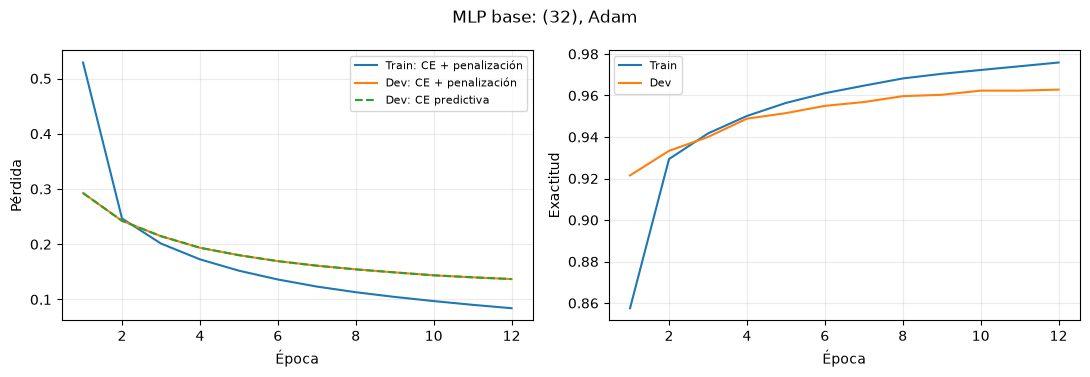

{'CE_dev': 0.13697059452533722, 'accuracy_dev': 0.9628333333333333, 'parametros': 25450}


In [10]:
def ce_dev(modelo, X, y, batch_size=1024):
    """Calcula la CE predictiva sin penalización L1/L2."""
    logits = modelo.predict(X, batch_size=batch_size, verbose=0)

    # Calcula internamente softmax + cross-entropy.
    ce = tf.keras.losses.sparse_categorical_crossentropy(
        y, logits, from_logits=True
    )
    return float(tf.reduce_mean(ce).numpy())


def evaluar_dev(modelo, X=X_dev, y=y_dev):
    """Evalúa CE, exactitud y número de parámetros en dev."""
    logits = modelo.predict(X, verbose=0)

    # Calcula CE directamente desde los logits.
    ce = tf.keras.losses.sparse_categorical_crossentropy(
        y, logits, from_logits=True
    )

    # La clase predicha corresponde al logit más alto.
    predicciones = np.argmax(logits, axis=1)

    return {
        'CE_dev': float(tf.reduce_mean(ce).numpy()),
        'accuracy_dev': accuracy_score(y, predicciones),
        'parametros': modelo.count_params()
    }


def entrenar(config=None, epocas=12, batch_size=128, paciencia=3, verbose=0):
    """Construye y entrena una MLP; selecciona los mejores pesos según CE de dev."""
    config = dict(config or {})

    # Fija la semilla para reproducir los experimentos.
    tf.keras.utils.set_random_seed(SEED)

    # Construye el modelo con los hiperparámetros indicados.
    modelo = crear_modelo(**config)

    # Calcula la CE predictiva en dev al finalizar cada época.
    class RegistrarCE(tf.keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs['val_ce'] = ce_dev(self.model, X_dev, y_dev)

    # Detiene el entrenamiento si la CE de dev deja de mejorar.
    detener = tf.keras.callbacks.EarlyStopping(
        monitor='val_ce',
        patience=paciencia,
        mode='min',
        restore_best_weights=True  # Recupera los mejores pesos.
    )

    # Entrena con mini-batches y valida después de cada época.
    historial = modelo.fit(
        X_train, y_train,
        validation_data=(X_dev, y_dev),
        epochs=epocas,
        batch_size=batch_size,
        callbacks=[RegistrarCE(), detener],
        verbose=verbose
    )

    return modelo, historial


def graficar_historial(historial, titulo='Entrenamiento'):
    """Grafica las pérdidas y exactitudes de train y dev."""
    h = historial.history
    e = range(1, len(h['loss']) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

    # Compara pérdida total y CE predictiva.
    ax[0].plot(e, h['loss'], label='Train: CE + penalización')
    ax[0].plot(e, h['val_loss'], label='Dev: CE + penalización')
    ax[0].plot(e, h['val_ce'], '--', label='Dev: CE predictiva')

    # Compara la exactitud de train y dev.
    ax[1].plot(e, h['accuracy'], label='Train')
    ax[1].plot(e, h['val_accuracy'], label='Dev')

    # Configura ejes y leyendas.
    for a, ylabel in zip(ax, ['Pérdida', 'Exactitud']):
        a.set(xlabel='Época', ylabel=ylabel)
        a.grid(alpha=0.25)
        a.legend(fontsize=8)

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


# Entrena la MLP base: una capa oculta de 32 neuronas y Adam.
modelo_base, historial_base = entrenar(epocas=12, verbose=1)

# Muestra las curvas de aprendizaje.
graficar_historial(historial_base, 'MLP base: (32), Adam')

# Evalúa CE, exactitud y parámetros en dev.
print(evaluar_dev(modelo_base))

### Interpretación del modelo base

- La CE disminuye tanto en train como en dev: **el modelo está aprendiendo**.
- La exactitud de dev alcanza **96.28 %**.
- La separación entre las curvas indica cierta brecha de generalización, pero **no hay sobreajuste evidente**, ya que la CE de dev sigue disminuyendo.
- El entrenamiento termina en la época 12 sin activar *early stopping*.

**Conclusión:** la MLP base ofrece un buen punto de referencia para comparar arquitecturas, optimizadores y técnicas de regularización.

## 5. Comparación controlada de optimizadores
La arquitectura y los datos son idénticos; únicamente cambia la regla de actualización. Elegimos tasas de aprendizaje ilustrativas (no equivalentes en escala) y luego ajustaremos mediante búsqueda. El optimizador que alcanza mayor exactitud en pocas épocas **no necesariamente** ofrece la menor CE.

El gráfico muestra CE de **dev por época**, para evitar confundir descenso de la pérdida total con descenso de CE.

Compara cuatro optimizadores utilizando la misma arquitectura (32 neuronas en capa oculta) y selecciona los resultados según la menor CE en dev.

---
Se mantiene la arquitectura, pero las tasas de aprendizaje son distintas porque cada optimizador puede funcionar mejor con diferentes valores. Por tanto, el experimento compara cuatro configuraciones de optimización, no exclusivamente el efecto del algoritmo.

,optimizador,CE_dev,accuracy_dev,parametros,epocas
1,Momentum,0.130409,0.966333,25450,10
3,Adam,0.131144,0.963833,25450,10
2,RMSprop,0.137440,0.961667,25450,10
0,SGD,0.208808,0.940000,25450,10


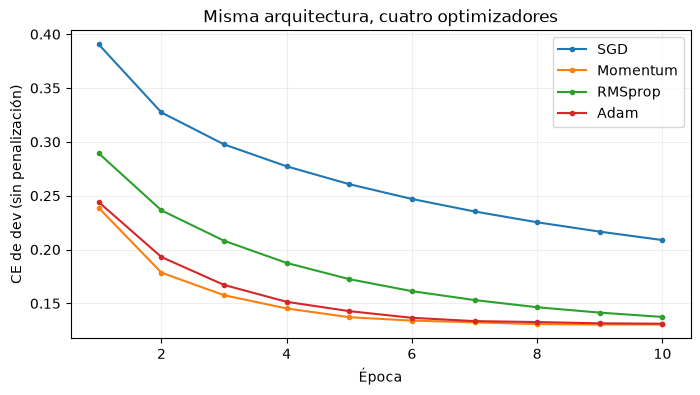

In [11]:
# Define los optimizadores y sus tasas de aprendizaje.
experimentos_opt = [
    ('SGD',      {'optimizador': 'sgd',      'learning_rate': 0.05}),
    ('Momentum', {'optimizador': 'momentum', 'learning_rate': 0.05, 'momentum': 0.9}),
    ('RMSprop',  {'optimizador': 'rmsprop',  'learning_rate': 0.001}),
    ('Adam',     {'optimizador': 'adam',     'learning_rate': 0.002}),
]

resultados_opt = []  # Almacena las métricas finales.
historias_opt = {}   # Almacena la CE de dev por época.

# Entrena la misma arquitectura (32 neuronas) con cada optimizador.
for nombre, params in experimentos_opt:

    modelo, hist = entrenar(
        {'capas': (32,), **params},
        epocas=10, paciencia=3
    )

    # Guarda las métricas y el número de épocas ejecutadas.
    resultados_opt.append({
        'optimizador': nombre,
        **evaluar_dev(modelo),
        'epocas': len(hist.history['loss'])
    })

    # Guarda la evolución de la CE en dev.
    historias_opt[nombre] = hist.history['val_ce']

# Ordena los resultados por menor CE en dev.
display(pd.DataFrame(resultados_opt).sort_values('CE_dev'))

# Compara las curvas de convergencia de los optimizadores.
plt.figure(figsize=(8, 4))

for nombre, serie in historias_opt.items():
    plt.plot(range(1, len(serie) + 1), serie, marker='.', label=nombre)

plt.xlabel('Época')
plt.ylabel('CE de dev (sin penalización)')
plt.title('Misma arquitectura, cuatro optimizadores')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Discusión:** Momentum acumula gradientes suavizados; RMSprop ajusta por magnitudes cuadráticas recientes; Adam combina ambas ideas. El experimento compara implementaciones de Keras, no su derivación matemática. `lr_decay=True` permite disminuir la tasa de aprendizaje durante el entrenamiento usando un calendario exponencial definido en `crear_modelo`.

### Interpretación de los optimizadores

- **Momentum** obtuvo la menor CE (0.1304) y mayor exactitud (96.63 %).
- **RMSprop y Adam** mostraron resultados similares.
- **SGD** presentó la convergencia más lenta.

**¿Significa que Momentum es siempre mejor que Adam?**

No. El desempeño depende de la tasa de aprendizaje, la arquitectura y las épocas de entrenamiento.

**Conclusión:** Momentum fue el mejor en este experimento, pero sería necesario ajustar los hiperparámetros para realizar una comparación más completa.

## 6. Regularización y batch normalization
Ahora cambiamos **una técnica por experimento**, manteniendo arquitectura y Adam. L1/L2 actúan sobre los pesos, dropout modifica las activaciones durante `fit`, y BN normaliza activaciones usando estadísticas de mini-batch en entrenamiento.

BN **no es idéntica a dropout** ni garantiza una mejor generalización. Es importante contrastar CE y accuracy de dev y observar tanto `loss` (objetivo penalizado) como `val_ce` (calidad predictiva).

,tecnica,CE_dev,accuracy_dev,parametros,epocas
2,L2,0.113901,0.968000,52650,12
4,BatchNorm,0.113981,0.966000,53034,8
3,Dropout 0.25,0.120193,0.966500,52650,12
0,Sin regularización,0.121649,0.968500,52650,12
1,L1,0.123830,0.966833,52650,12


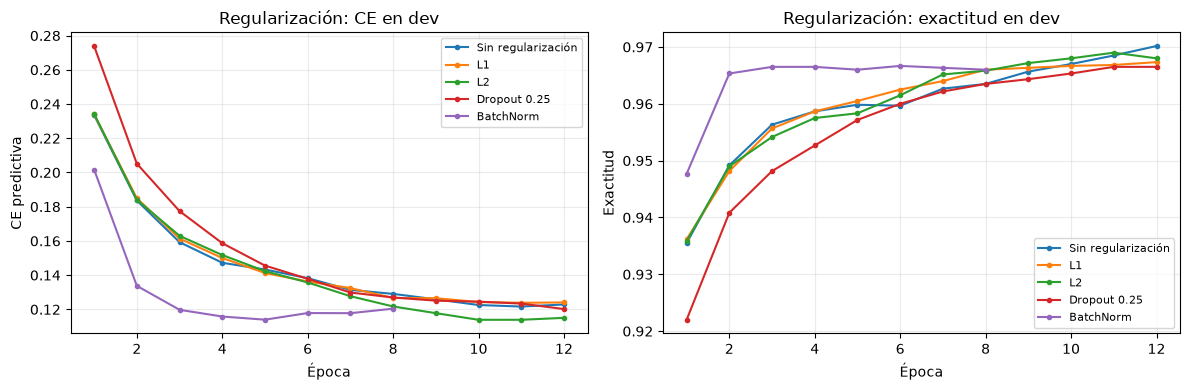

In [12]:
# Define las técnicas que se compararán.
experimentos_reg = [
    ('Sin regularización', {}),
    ('L1', {'l1': 1e-5}),
    ('L2', {'l2': 1e-4}),
    ('Dropout 0.25', {'dropout': 0.25}),
    ('BatchNorm', {'batch_norm': True}),
]

resultados_reg = []  # Guarda las métricas finales.
historias_reg = {}   # Guarda las curvas de aprendizaje.

# Entrena la misma arquitectura (64, 32) con cada técnica.
for nombre, cambio in experimentos_reg:

    modelo, hist = entrenar(
        {'capas': (64, 32), **cambio},
        epocas=12, paciencia=3
    )

    # Guarda CE, exactitud, parámetros y épocas ejecutadas.
    resultados_reg.append({
        'tecnica': nombre,
        **evaluar_dev(modelo),
        'epocas': len(hist.history['loss'])
    })

    # Guarda el historial para graficar sin volver a entrenar.
    historias_reg[nombre] = hist.history

# Muestra los resultados ordenados por menor CE de dev.
display(pd.DataFrame(resultados_reg).sort_values('CE_dev'))


# Compara las curvas de CE y exactitud en dev.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for nombre, h in historias_reg.items():
    epocas = range(1, len(h['val_ce']) + 1)

    # Evolución de la CE predictiva.
    ax[0].plot(epocas, h['val_ce'], marker='.', label=nombre)

    # Evolución de la exactitud.
    ax[1].plot(epocas, h['val_accuracy'], marker='.', label=nombre)

# Configura las gráficas.
ax[0].set(
    title='Regularización: CE en dev',
    xlabel='Época',
    ylabel='CE predictiva'
)

ax[1].set(
    title='Regularización: exactitud en dev',
    xlabel='Época',
    ylabel='Exactitud'
)

for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()

IMPORTANTE: **¿Por qué el modelo con menor CE no tiene necesariamente mayor exactitud?**

La CE considera la confianza de las predicciones, mientras que la exactitud solo cuenta las clasificaciones correctas.

Seleccionamos el modelo con menor CE de *dev*, sin utilizar *test*. La exactitud es una métrica complementaria.

### Interpretación de los resultados

- **BatchNorm:** alcanza la menor CE de dev y converge en menos épocas.
- **L2:** obtiene la mayor exactitud (97.00 %), prácticamente igual al modelo sin regularización.
- **L1 y dropout:** no mejoran al modelo base con los hiperparámetros utilizados.

**¿Qué aprendimos?**

Las técnicas de regularización no siempre mejoran el desempeño. Su efectividad depende de la arquitectura, los hiperparámetros y el entrenamiento.

**Conclusión:** según nuestro criterio de menor CE en dev, seleccionamos BatchNorm. Sin embargo, L2 ofrece una alternativa competitiva y todavía podría mejorar con más épocas.

## 7. Búsqueda aleatoria de hiperparámetros
En lugar de probar una cuadrícula enorme, tomamos muestras aleatorias de un espacio de configuraciones. Esto implementa una versión didáctica de *random search*.

Para presupuestos comparables, todas las pruebas usan el mismo límite de épocas y los mismos datos. El espacio mezcla arquitectura, optimizador, LR, mini-batch y regularización. Usamos **una sola técnica regularizadora** por configuración para facilitar la interpretación.

**Costo:** con `N_PRUEBAS=6` se entrenan seis MLP; baja a 3 si tu equipo es lento, o aumenta cuando dispongas de GPU. Evitamos optimizar sobre test.

In [13]:
# Presupuesto de búsqueda: 6 configuraciones, máximo 10 épocas cada una.
N_PRUEBAS = 6
EPOCAS_BUSQUEDA = 10
rng = np.random.default_rng(SEED)  # Semilla para reproducir el muestreo.


def muestrear_configuracion(rng):
    """Genera una combinación aleatoria de hiperparámetros."""

    # Selecciona optimizador y técnica de regularización.
    opt = str(rng.choice(['sgd', 'momentum', 'rmsprop', 'adam']))
    reg = str(rng.choice(['ninguna', 'l1', 'l2', 'dropout']))

    # Inicialmente, sin regularización.
    valores = {'l1': 0.0, 'l2': 0.0, 'dropout': 0.0}

    # Muestrea la intensidad de regularización seleccionada.
    if reg == 'l1':
        valores['l1'] = float(10 ** rng.uniform(-6, -4))
    elif reg == 'l2':
        valores['l2'] = float(10 ** rng.uniform(-6, -3))
    elif reg == 'dropout':
        valores['dropout'] = float(rng.uniform(0.1, 0.4))

    # Define el rango de learning rate según el optimizador.
    limite_lr = (-2.5, -1.0) if opt in ('sgd', 'momentum') else (-4.0, -2.5)

    # Genera una configuración aleatoria de la MLP.
    return {
        'capas': [(32,), (64, 32), (128, 64)][int(rng.integers(0, 3))],
        'activacion': str(rng.choice(['relu', 'tanh'])),
        'optimizador': opt,
        'learning_rate': float(10 ** rng.uniform(*limite_lr)),  # Escala logarítmica.
        'batch_norm': bool(rng.choice([False, True])),
        **valores  # Incorpora L1, L2 o dropout.
    }


ensayos = []                  # Resultados de cada configuración.
modelos_busqueda = {}         # Modelos entrenados.
historias_busqueda = {}       # Historiales de entrenamiento.
configuraciones_busqueda = [] # Hiperparámetros probados.

# Ejecuta la búsqueda aleatoria.
for i in range(N_PRUEBAS):

    cfg = muestrear_configuracion(rng)  # Selecciona hiperparámetros.
    t = int(rng.choice([64, 128, 256]))  # Tamaño del mini-batch.
    nombre = f'ensayo_{i+1:02d}'

    print(f'{nombre}: {cfg} | batch_size={t}')

    # Entrena el modelo y restaura los mejores pesos según CE de dev.
    modelo, hist = entrenar(
        cfg, epocas=EPOCAS_BUSQUEDA, batch_size=t, paciencia=3
    )

    # Evalúa el modelo en dev, sin utilizar test.
    metricas = evaluar_dev(modelo)

    # Registra métricas e hiperparámetros del ensayo.
    ensayos.append({
        'ensayo': nombre,
        **metricas,
        'capas': str(cfg['capas']),
        'optimizador': cfg['optimizador'],
        'lr': cfg['learning_rate'],
        'batch_size': t,
        'BN': cfg['batch_norm'],
        'L1': cfg['l1'],
        'L2': cfg['l2'],
        'dropout': cfg['dropout'],
        'epocas': len(hist.history['loss'])
    })

    # Conserva configuración, modelo e historial de cada ensayo.
    configuraciones_busqueda.append(cfg)
    modelos_busqueda[nombre] = modelo
    historias_busqueda[nombre] = hist

# Ordena los ensayos de menor a mayor CE predictiva en dev.
tabla_busqueda = pd.DataFrame(ensayos).sort_values('CE_dev').reset_index(drop=True)
display(tabla_busqueda.round(5))

ensayo_01: {'capas': (64, 32), 'activacion': 'tanh', 'optimizador': 'sgd', 'learning_rate': 0.0351602572225049, 'batch_norm': False, 'l1': 0.0, 'l2': 0.0, 'dropout': 0.23166353192561573} | batch_size=64
ensayo_02: {'capas': (128, 64), 'activacion': 'tanh', 'optimizador': 'rmsprop', 'learning_rate': 0.00015565764265126965, 'batch_norm': True, 'l1': 0.0, 'l2': 0.0, 'dropout': 0.32834191059710593} | batch_size=128
ensayo_03: {'capas': (128, 64), 'activacion': 'tanh', 'optimizador': 'rmsprop', 'learning_rate': 0.0017145194644738026, 'batch_norm': True, 'l1': 7.137234690401966e-05, 'l2': 0.0, 'dropout': 0.0} | batch_size=128
ensayo_04: {'capas': (32,), 'activacion': 'tanh', 'optimizador': 'momentum', 'learning_rate': 0.003942084090215385, 'batch_norm': True, 'l1': 0.0, 'l2': 0.0, 'dropout': 0.0} | batch_size=256
ensayo_05: {'capas': (128, 64), 'activacion': 'relu', 'optimizador': 'momentum', 'learning_rate': 0.09037473494622139, 'batch_norm': False, 'l1': 0.0, 'l2': 0.0001880456191611349, '

,ensayo,CE_dev,accuracy_dev,parametros,capas,optimizador,lr,batch_size,BN,L1,L2,dropout,epocas
0,ensayo_05,0.09707,0.97217,109386,"(128, 64)",momentum,0.09037,256,False,0.00000,0.00019,0.00000,8
1,ensayo_03,0.14362,0.96117,110154,"(128, 64)",rmsprop,0.00171,128,True,0.00007,0.00000,0.00000,7
2,ensayo_06,0.16104,0.95167,53034,"(64, 32)",rmsprop,0.00012,64,True,0.00000,0.00000,0.15839,10
3,ensayo_01,0.19450,0.94383,52650,"(64, 32)",sgd,0.03516,64,False,0.00000,0.00000,0.23166,10
4,ensayo_02,0.20908,0.93667,110154,"(128, 64)",rmsprop,0.00016,128,True,0.00000,0.00000,0.32834,10
5,ensayo_04,0.26268,0.92700,25578,"(32,)",momentum,0.00394,256,True,0.00000,0.00000,0.00000,10


### Interpretación de la búsqueda aleatoria

- **Ensayo 05:** obtuvo la menor CE (0.1034) y la mayor exactitud (97.07 %).
- Su configuración combina una red (128, 64), ReLU, Momentum y regularización L2.
- Superó al modelo base, aunque utiliza más parámetros.
- Los demás ensayos muestran que distintas combinaciones de hiperparámetros producen resultados muy diferentes.

**¿Qué aprendimos?**

La búsqueda aleatoria permite explorar combinaciones de arquitectura, optimizador, regularización y tasa de aprendizaje sin probar todas las posibilidades.

**Conclusión:** seleccionamos el ensayo 05 por su menor CE de dev. Es el mejor de los seis ensayos, pero no necesariamente la configuración óptima.

### Selección del modelo
La elección usa exclusivamente `CE_dev` de **los pesos restaurados**. La exactitud es útil para interpretar una posible discrepancia; CE penaliza predicciones incorrectas con mucha confianza. La configuración del ensayo ganador queda registrada. **No consultes test mientras revisas las pruebas.**

Si deseas hacer nuevas búsquedas, ejecútalas **antes** de la celda de evaluación final. Muchos intentos sobre el mismo dev pueden sobreajustar indirectamente esa partición: limita el presupuesto y documenta los intentos.

Ganador: ensayo_05
Configuración: {'capas': (128, 64), 'activacion': 'relu', 'optimizador': 'momentum', 'learning_rate': 0.09037473494622139, 'batch_norm': False, 'l1': 0.0, 'l2': 0.0001880456191611349, 'dropout': 0.0}
Métricas DEV del ganador: {'CE_dev': 0.09706850349903107, 'accuracy_dev': 0.9721666666666666, 'parametros': 109386}


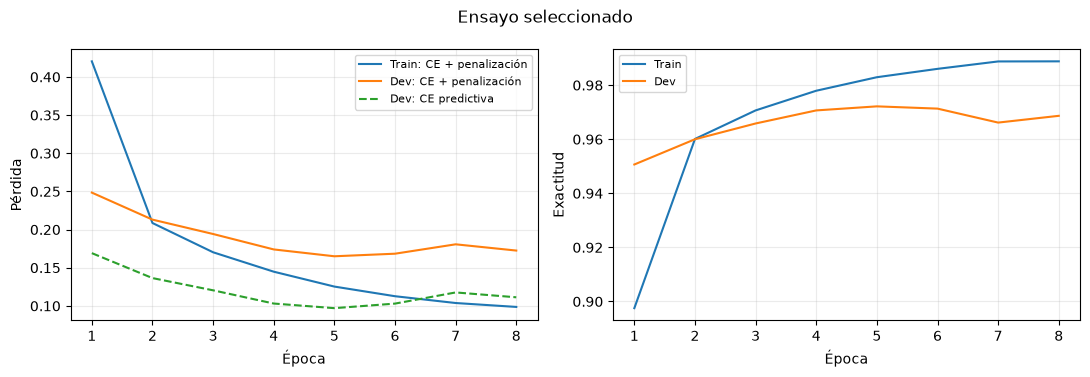

In [14]:
# Selecciona el ensayo con menor CE en dev.
ganador = tabla_busqueda.iloc[0]
nombre_ganador = ganador['ensayo']

# Recupera el modelo ganador con sus mejores pesos restaurados.
modelo_final = modelos_busqueda[nombre_ganador]

# Recupera los hiperparámetros utilizados en ese ensayo.
config_final = configuraciones_busqueda[
    int(nombre_ganador.split('_')[1]) - 1
]

# Muestra la configuración y las métricas del modelo seleccionado.
print('Ganador:', nombre_ganador)
print('Configuración:', config_final)
print('Métricas DEV del ganador:', evaluar_dev(modelo_final))

# Grafica su evolución durante el entrenamiento.
graficar_historial(
    historias_busqueda[nombre_ganador],
    'Ensayo seleccionado'
)

## 8. Evaluación final en TEST (solo cuando la selección esté cerrada)
Esta celda es la **única** que utiliza las imágenes y etiquetas `X_test`/`y_test` para evaluar. No modificamos arquitectura, optimizador, umbrales ni hiperparámetros a partir del resultado. Informamos CE, exactitud, reporte por clase y matriz de confusión.

Modelo: ensayo_05
Exactitud TEST: 0.9743
CE TEST: 0.0793
              precision    recall  f1-score   support

           0      0.976     0.993     0.984       980
           1      0.995     0.988     0.991      1135
           2      0.974     0.977     0.975      1032
           3      0.963     0.977     0.970      1010
           4      0.984     0.968     0.976       982
           5      0.980     0.939     0.959       892
           6      0.977     0.979     0.978       958
           7      0.979     0.966     0.973      1028
           8      0.958     0.973     0.965       974
           9      0.956     0.977     0.967      1009

    accuracy                          0.974     10000
   macro avg      0.974     0.974     0.974     10000
weighted avg      0.974     0.974     0.974     10000



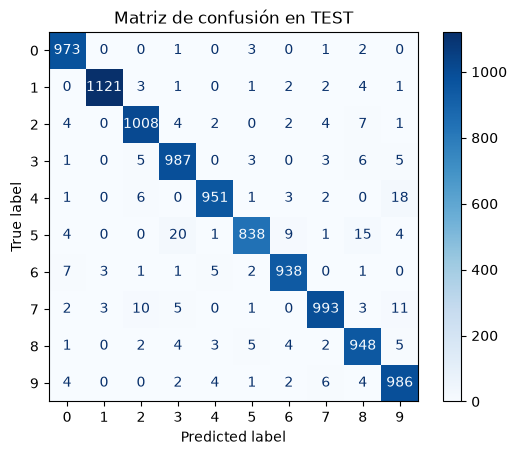

In [15]:
logits_test = modelo_final.predict(X_test, verbose=0)
prob_test = tf.nn.softmax(logits_test, axis=1).numpy()
pred_test = np.argmax(prob_test, axis=1)
print('Modelo:', nombre_ganador)
print('Exactitud TEST:', round(accuracy_score(y_test, pred_test), 4))
print('CE TEST:', round(log_loss(y_test, prob_test, labels=np.arange(10)), 4))
print(classification_report(y_test, pred_test, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, cmap='Blues', values_format='d')
plt.title('Matriz de confusión en TEST'); plt.show()

### Errores visuales
Analiza algunos errores sin ajustar otra vez el modelo. Puedes explicar qué trazos se parecen entre dos dígitos. Este análisis final caracteriza la generalización; si genera nuevas hipótesis, deberán probarse en **un experimento nuevo** con un test independiente.

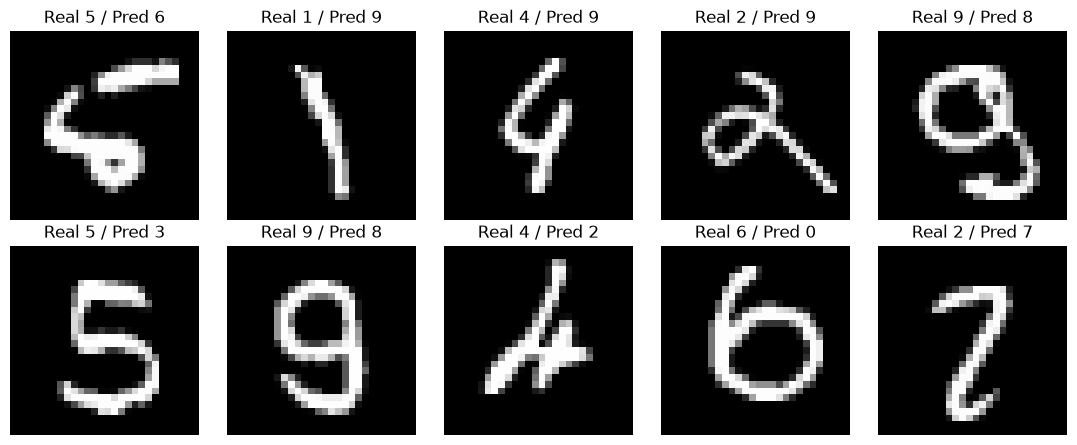

In [16]:
indices_error = np.flatnonzero(pred_test != y_test)[:10]
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for ax in axes.flat:
    ax.axis('off')
for ax, j in zip(axes.flat, indices_error):
    ax.imshow(X_test[j], cmap='gray')
    ax.set_title(f'Real {y_test[j]} / Pred {pred_test[j]}')
plt.tight_layout(); plt.show()

---
## 9. Práctica individual: **preguntas diferentes, mismo rigor**
No repetirán todos el mismo experimento. **Cada estudiante elige una pregunta libre de esta tabla (sin duplicados por grupo), formula hipótesis y compara **3–5 configuraciones** cambiando preferentemente **un factor por vez**. Puede después aplicar random search en su propia ruta.

### Rutas prioritarias de investigación

Estas investigaciones abordan las principales decisiones del modelado y entrenamiento de redes neuronales.

| Ruta | Pregunta de investigación | Variable principal |
|---|---|---|
| A | ¿Red ancha o profunda con presupuesto similar? | Capas y parámetros |
| B | ¿He contra Glorot con ReLU? | Inicialización |
| E | ¿Qué intensidad L2 generaliza mejor? | Coeficiente L2 |
| F | ¿Cuándo dropout es excesivo? | Tasa de dropout |
| G | ¿BatchNorm mejora la estabilidad y convergencia? | BN sí/no |
| H | ¿Momentum supera a SGD sin momentum? | Optimizador |
| I | ¿Adam o RMSprop con tasas ajustadas? | Optimizador y LR |
| K | ¿Qué tamaño de mini-batch conviene? | t = 32, 128, 512 |
| L | ¿Qué sensibilidad tiene el learning rate? | LR en escala logarítmica |
| P | ¿La búsqueda aleatoria supera a la elección manual? | Estrategia de selección |

### Rutas complementarias de investigación

Estas investigaciones permiten profundizar en funciones de activación, regularización, eficiencia y análisis de resultados.

| Ruta | Pregunta de investigación | Variable principal |
|---|---|---|
| C | ¿ReLU contra tanh con el mismo tamaño? | Función de activación |
| D | ¿Cuánto ayuda L1? | Coeficiente L1 |
| J | ¿Cómo cambia el comportamiento con learning rate decay? | Decay sí/no |
| M | ¿Mayor número de parámetros siempre ayuda? | Capacidad del modelo |
| N | ¿Qué métrica elegiría un modelo diferente? | CE frente a accuracy |
| O | ¿Qué dígitos se confunden más en dev? | Análisis de errores |

-----
### Práctica individual: exploración de modelos MLP

Cada estudiante deberá elegir:

- **2 rutas prioritarias** de investigación.
- **1 ruta complementaria** de investigación.

**Regla:** no seleccionar la misma combinación de investigaciones que los compañeros cercanos. El propósito es exponer diferentes experimentos, resultados y conclusiones.

-----

**Entrega:** hipótesis → estrategia (qué se mantuvo constante) → tabla comparativa de dev → curvas y matriz de confusión **en dev** → conclusión con limitaciones. Máximo **5 minutos de exposición**.

--------


**Regla importante:** el test no forma parte del trabajo exploratorio; una vez elegida una configuración, evaluar en test y reportar resultados, sin reajustar. Cada quien deberá reportar su semilla y presupuesto de entrenamiento.

### Plantilla para la investigación (editar esta celda de código)
La plantilla **no consulta test**. Cambia `opciones` según tu ruta; evita usar el conjunto de prueba (test) para escoger el ganador. Si investigas tamaño del mini-batch, modifica el segundo valor de cada tupla.

In [17]:
# Ejemplo: ruta F, efecto de dropout (puedes reemplazar la lista completa).
opciones = [
    ('Sin dropout', {'capas': (64, 32), 'dropout': 0.0}, 128),
    ('Dropout 0.2', {'capas': (64, 32), 'dropout': 0.2}, 128),
    ('Dropout 0.5', {'capas': (64, 32), 'dropout': 0.5}, 128),
]
resultados_estudiante = []
for etiqueta, cfg, tamano_batch in opciones:
    mod, hist = entrenar(cfg, epocas=12, batch_size=tamano_batch, paciencia=3)
    resultados_estudiante.append({'experimento': etiqueta,
                                  **evaluar_dev(mod),
                                  'epocas': len(hist.history['loss']),
                                  'mini_batch': tamano_batch})
display(pd.DataFrame(resultados_estudiante).sort_values('CE_dev'))

,experimento,CE_dev,accuracy_dev,parametros,epocas,mini_batch
1,Dropout 0.2,0.112219,0.970667,52650,12,128
0,Sin dropout,0.121649,0.968500,52650,12,128
2,Dropout 0.5,0.179981,0.954000,52650,12,128


### Exposición de resultados (3 minutos por estudiante)

Presenta **el hallazgo más interesante** de tus tres investigaciones, respondiendo:

1. **¿Qué investigaste?** Indica la variable modificada y tu hipótesis.
2. **¿Qué encontraste?** Muestra una gráfica y compara CE y exactitud en dev.
3. **¿Qué concluyes?** ¿Se cumplió tu hipótesis? ¿Por qué?
4. **¿Qué mejorarías?** Propón un nuevo experimento para confirmar tus resultados.

**Importante:** no es necesario explicar el código. La exposición debe centrarse en los resultados, su interpretación y las decisiones de modelado.


# Parte de Kevin
## Varibles de control
- SEED=42
- Optimizador: Adam
- Learning rate = $0.001$
- Paciencia = 3


## Hipotesis 

Las rutas tomadas por mi parte fueron:

1. **K:** ¿Qué tamaño de mini-batch conviene? | t = 32, 128, 512 
2. **P:** ¿La búsqueda aleatoria supera a la elección manual?
3. **O:** ¿Qué dígitos se confunden más en dev?

---
Para la cual pienso que dependiendo del tipo de problema que se tengamos el tamaño del minibatch es importante, ya que un batch muy grande podria tardar bastante tiempo.

- Batches pequeños (32) actúan como regularizador estocástico pero tardan más tiempo por época;

- Batches grandes (512) convergen más rápido por época pero pueden degradar 'val_ce' al caer en mínimos menos generalizables.
--- 
La exploración estocástica del espacio multivariable (LR, L2, Dropout, Ancho)
encontrará configuraciones con menor 'val_ce' que el ajuste intuitivo manual en un presupuesto de N=5 intentos.

---
Muchas veces por percibir un mejor número en las metricas de evaluacion tomaremos que ese será el mejor modelo para los hiperparametros, y despreciamos la informacion que puedan tener estos. 

## Ruta K: Tamaño de Mini-Batch
En esta ruta se mantiene fija la arquitectura (748->64->32->10) y la tasa de aprendizaje (alpha = 0.001), variando únicamente el tamaño del lote.

,experimento,CE_dev,accuracy_dev,parametros,epocas_efectivas,tiempo_seg,mini_batch
3,Batch 256,0.116661,0.967167,52650,14,4.58,256
4,Batch 512,0.120197,0.965667,52650,15,3.72,512
2,Batch 128,0.121649,0.968500,52650,14,6.99,128
1,Batch 32,0.122371,0.970167,52650,12,15.91,32
0,Batch 16,0.129892,0.966667,52650,8,19.26,16


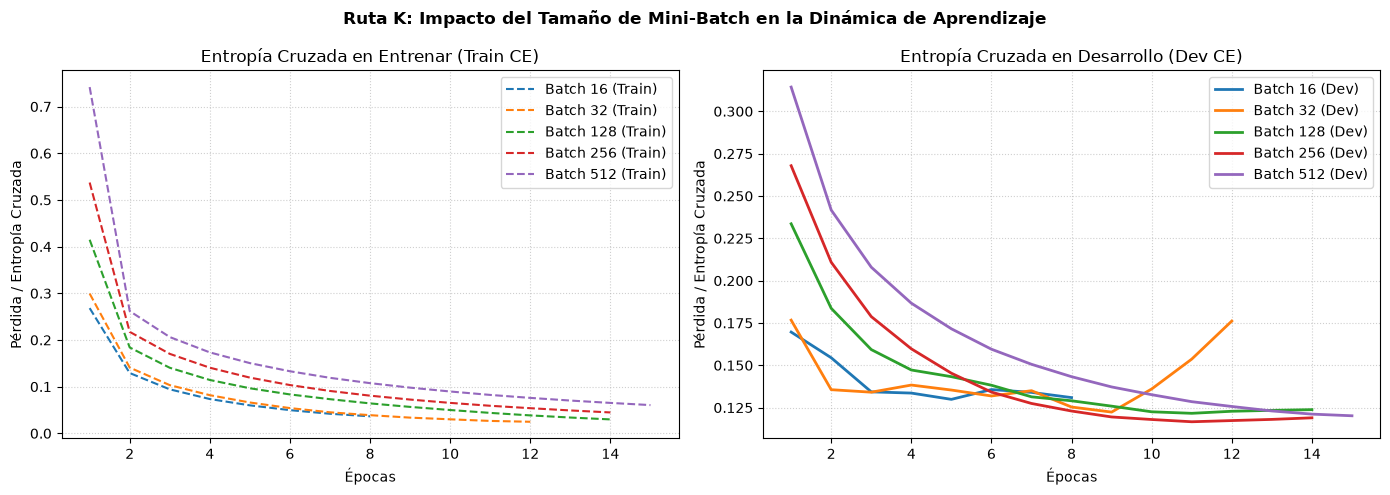

In [19]:
import time

opciones_K = [
    ('Batch 16',  {'capas': (64, 32), 'optimizador': 'adam', 'learning_rate': 1e-3}, 16),
    ('Batch 32',  {'capas': (64, 32), 'optimizador': 'adam', 'learning_rate': 1e-3}, 32),
    ('Batch 128', {'capas': (64, 32), 'optimizador': 'adam', 'learning_rate': 1e-3}, 128),
    ('Batch 256', {'capas': (64, 32), 'optimizador': 'adam', 'learning_rate': 1e-3}, 256),
    ('Batch 512', {'capas': (64, 32), 'optimizador': 'adam', 'learning_rate': 1e-3}, 512),
]

resultados_K = []
historias_K = {}

for etiqueta, cfg, tamano_batch in opciones_K:
    t_inicio = time.time()
    mod, hist = entrenar(cfg, epocas=15, batch_size=tamano_batch, paciencia=3)
    t_total = time.time() - t_inicio
    
    historias_K[etiqueta] = hist.history
    
    resultados_K.append({
        'experimento': etiqueta,
        **evaluar_dev(mod),
        'epocas_efectivas': len(hist.history['loss']),
        'tiempo_seg': round(t_total, 2),
        'mini_batch': tamano_batch
    })

# 1. Tabla comparativa
df_K = pd.DataFrame(resultados_K).sort_values('CE_dev')
display(df_K)

# 2. Generación de Curvas de Aprendizaje (Dev)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for etiqueta, hist in historias_K.items():
    epocas = range(1, len(hist['loss']) + 1)
    # Obtener llave de entropía cruzada pura en dev
    ce_dev_key = 'val_ce' if 'val_ce' in hist else 'val_loss'
    ce_train_key = 'train_ce' if 'train_ce' in hist else 'loss'
    
    ax1.plot(epocas, hist[ce_train_key], linestyle='--', label=f'{etiqueta} (Train)')
    ax2.plot(epocas, hist[ce_dev_key], linewidth=2, label=f'{etiqueta} (Dev)')

ax1.set_title('Entropía Cruzada en Entrenar (Train CE)')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Pérdida / Entropía Cruzada')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.set_title('Entropía Cruzada en Desarrollo (Dev CE)')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Pérdida / Entropía Cruzada')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.suptitle('Ruta K: Impacto del Tamaño de Mini-Batch en la Dinámica de Aprendizaje', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Ruta P: Búsqueda Aleatoria vs. Selección Manual
Se define un espacio de búsqueda continuo para muestrear combinaciones de hiperparámetros ($\alpha$, $p$, $\lambda_2$, anchos de capa) y comparar sus resultados contra el modelo base ajustado manualmente.

,experimento,CE_dev,accuracy_dev,parametros,capas,learning_rate,dropout,l2,epocas
8,RandomSearch_8,0.100629,0.972167,52650,"(64, 32)",7.71e-04,0.1,0.0000,15
4,RandomSearch_4,0.114589,0.967500,109386,"(128, 64)",3.33e-03,0.2,0.0010,14
1,RandomSearch_1,0.114729,0.967167,56810,"(64, 64, 32)",3.53e-03,0.2,0.0001,15
7,RandomSearch_7,0.116488,0.966833,104938,"(128, 32)",1.94e-03,0.1,0.0010,8
2,RandomSearch_2,0.120663,0.965667,109386,"(128, 64)",5.21e-03,0.0,0.0010,13
3,RandomSearch_3,0.123668,0.965167,109386,"(128, 64)",1.54e-04,0.2,0.0010,15
6,RandomSearch_6,0.123731,0.965667,52650,"(64, 32)",5.52e-04,0.0,0.0010,15
0,Manual (Baseline),0.133984,0.963833,25818,"(32, 16)",1.00e-03,0.0,0.0000,15
5,RandomSearch_5,0.182587,0.946333,52650,"(64, 32)",1.80e-04,0.3,0.0001,15


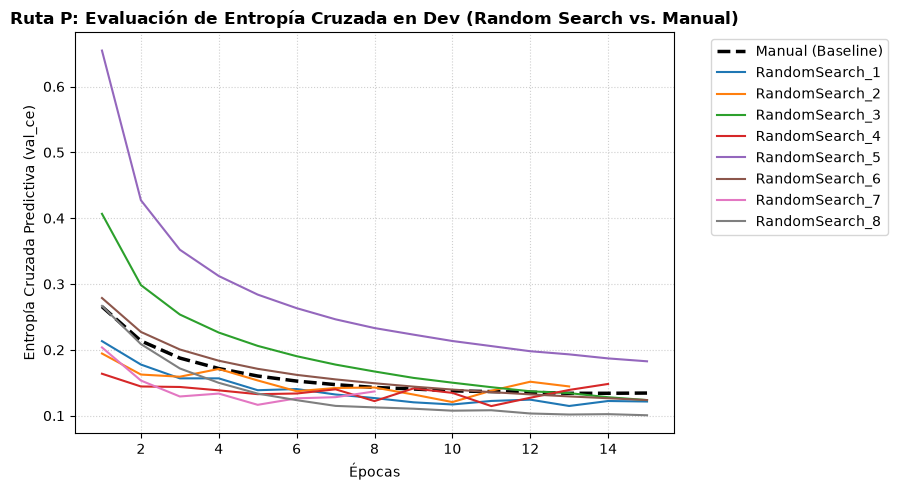

In [20]:
import random

opciones_P = [
    ('Manual (Baseline)', {'capas': (32, 16), 'learning_rate': 1e-3, 'dropout': 0.0, 'l2': 0.0}, 128)
]

rng = np.random.default_rng(SEED)
NUM_EXPERIMENTOS_RS = 8

for i in range(1, NUM_EXPERIMENTOS_RS + 1):
    capas_candidatas = random.choice([(64, 32), (128, 64), (64, 64, 32), (128, 32)])
    lr_candidato = float(10 ** rng.uniform(-4, -2))
    dropout_candidato = float(rng.choice([0.0, 0.1, 0.2, 0.3]))
    l2_candidato = float(rng.choice([0.0, 1e-4, 1e-3]))
    
    cfg_rs = {
        'capas': capas_candidatas,
        'learning_rate': lr_candidato,
        'dropout': dropout_candidato,
        'l2': l2_candidato,
        'optimizador': 'adam'
    }
    opciones_P.append((f'RandomSearch_{i}', cfg_rs, 128))

resultados_P = []
modelos_P = {}
historias_P = {}

for etiqueta, cfg, tamano_batch in opciones_P:
    mod, hist = entrenar(cfg, epocas=15, batch_size=tamano_batch, paciencia=3)
    modelos_P[etiqueta] = mod
    historias_P[etiqueta] = hist.history
    
    resultados_P.append({
        'experimento': etiqueta,
        **evaluar_dev(mod),
        'capas': str(cfg['capas']),
        'learning_rate': f"{cfg['learning_rate']:.2e}",
        'dropout': cfg['dropout'],
        'l2': cfg['l2'],
        'epocas': len(hist.history['loss'])
    })

# 1. Tabla comparativa
df_P = pd.DataFrame(resultados_P).sort_values('CE_dev')
display(df_P)

# 2. Generación de Curvas Comparativas (Dev CE)
plt.figure(figsize=(9, 5))

for etiqueta, hist in historias_P.items():
    epocas = range(1, len(hist['loss']) + 1)
    ce_dev_key = 'val_ce' if 'val_ce' in hist else 'val_loss'
    
    estilo = 'k--' if 'Manual' in etiqueta else '-'
    ancho = 2.5 if 'Manual' in etiqueta else 1.5
    
    plt.plot(epocas, hist[ce_dev_key], estilo, linewidth=ancho, label=etiqueta)

plt.title('Ruta P: Evaluación de Entropía Cruzada en Dev (Random Search vs. Manual)', fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Entropía Cruzada Predictiva (val_ce)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Ruta O: Análisis de Errores de Clasificación en Dev
Utiliza el modelo ganador obtenido en las pruebas anteriores para evaluar la Matriz de Confusión y extraer visualmente las muestras con fallos de predicción

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step


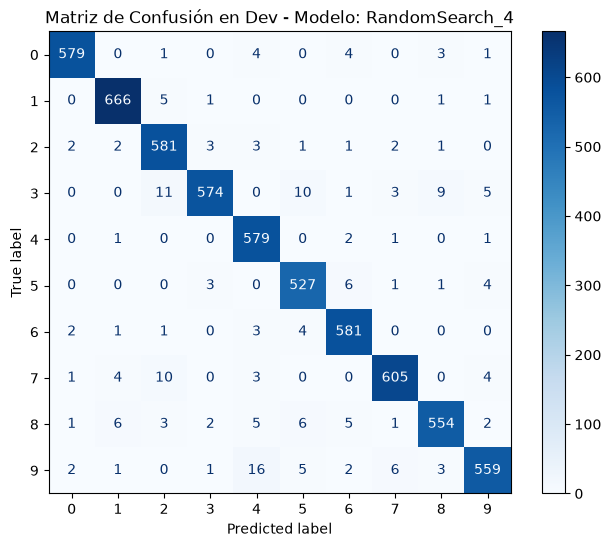

Total de errores en Dev: 195 de 6000 (Accuracy: 0.9675)


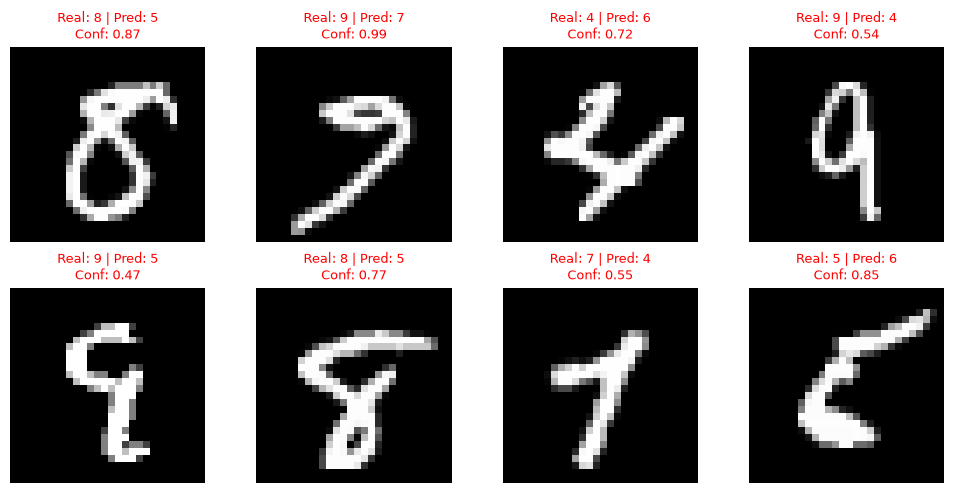

In [61]:
ganador_etiqueta = df_P.iloc[0]['experimento']
modelo_optimo = modelos_P[ganador_etiqueta]

# Obtención de logits y predicciones en la partición Dev
logits_dev = modelo_optimo.predict(X_dev, batch_size=128)
y_pred_dev = np.argmax(logits_dev, axis=1)

# 1. Matriz de Confusión
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_dev, y_pred_dev, cmap='Blues', ax=ax)
ax.set_title(f'Matriz de Confusión en Dev - Modelo: {ganador_etiqueta}')
plt.show()

# 2. Identificación de parejas de clases con mayor confusión y muestra visual de errores
indices_errores = np.where(y_pred_dev != y_dev)[0]
print(f'Total de errores en Dev: {len(indices_errores)} de {len(y_dev)} (Accuracy: {1 - len(indices_errores)/len(y_dev):.4f})')

# Graficar 8 ejemplos mal clasificados con alta confianza
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for idx, ax in zip(indices_errores[:8], axes.flat):
    ax.imshow(X_dev[idx], cmap='gray')
    prob_alta = tf.nn.softmax(logits_dev[idx])[y_pred_dev[idx]].numpy()
    ax.set_title(f'Real: {y_dev[idx]} | Pred: {y_pred_dev[idx]}\nConf: {prob_alta:.2f}', color='red', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()